### Business Questions
1. Total sales revenue?
2. Total quantity sold?
3. Monthly sales overtime?
4. Highest sales day of the week?
5. How much unknown or missing data?
6. Best selling items by revenue and quantity
7. Sales breakdown by payment method and order type

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns',20)
pd.set_option('display.max_row',30)

Data_PATH = Path('dirty_cafe_sales.csv')

raw = pd.read_csv(Data_PATH,dtype='string',keep_default_na=False)

In [2]:
print('Rows,Columns:', raw.shape)
print('Columns:',raw.columns.tolist())

Rows,Columns: (10000, 8)
Columns: ['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']


In [3]:
display(raw.head(10))
print("")
raw.info()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,,5,3.0,15.0,,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,,In-store,2023-12-31



<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  string
 1   Item              10000 non-null  string
 2   Quantity          10000 non-null  string
 3   Price Per Unit    10000 non-null  string
 4   Total Spent       10000 non-null  string
 5   Payment Method    10000 non-null  string
 6   Location          10000 non-null  string
 7   Transaction Date  10000 non-null  string
dtypes: string(8)
memory usage: 1.0 MB


In [4]:
for column in raw.columns:
    blank_count =  raw[column].str.strip().eq('').sum()
    print(column,":",blank_count)
    

Transaction ID : 0
Item : 333
Quantity : 138
Price Per Unit : 179
Total Spent : 173
Payment Method : 2579
Location : 3265
Transaction Date : 159


In [5]:
display(raw['Item'].value_counts(dropna=False))

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
             333
ERROR        292
Name: count, dtype: int64[pyarrow]

In [6]:
for  column in ['Payment Method','Location']:
    # print("Column", column)

    display(raw[column].value_counts(dropna=False))
    print("   ")
    print(" ")

Payment Method
                  2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64[pyarrow]

Location
            3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64[pyarrow]

### Check Quantity Conversion

In [7]:
quantity_text = raw["Quantity"].str.strip()

quantity_number = pd.to_numeric(quantity_text,errors="coerce")

blank = quantity_text.eq("")
invalid_text = quantity_text.ne("") & quantity_number.isna()

print("Blank", blank.sum())
print("Non blank but cannot convert:",invalid_text.sum())

print("")
display(quantity_text[invalid_text].value_counts(dropna=False))

Blank 138
Non blank but cannot convert: 341



Quantity
UNKNOWN    171
ERROR      170
Name: count, dtype: int64[pyarrow]

### Validate Quantity Values

In [8]:
quantity = quantity_number.dropna()

print("Numeric row:", len(quantity))
print("Min:", quantity.min())
print("Max:", quantity.max())

print("Zero:", (quantity == 0 ).sum())
print("Negative:",(quantity < 0 ).sum())
print("Fractional:", (quantity % 1 != 0 ).sum())

Numeric row: 9521
Min: 1.0
Max: 5.0
Zero: 0
Negative: 0
Fractional: 0


### Check Unit Price

In [9]:
price_text = raw["Price Per Unit"].str.strip()
price_number = pd.to_numeric(price_text, errors="coerce")

blank_price = price_text.eq("")
unreadable_price = price_text.ne("") & price_number.isna()

print("Blank:", blank_price.sum())
print("Non-Blank but cann't convert:",unreadable_price.sum())

display(price_text[unreadable_price].value_counts())

price = price_number.dropna()

print("Numeric row:", len(price))
print("Min:", price.min())
print("Max:", price.max())

print("Zero:", (price == 0 ).sum())
print("Negative:",(price < 0 ).sum())
print("Fractional:", (price % 1 != 0 ).sum())

Blank: 179
Non-Blank but cann't convert: 354


Price Per Unit
ERROR      190
UNKNOWN    164
Name: count, dtype: int64[pyarrow]

Numeric row: 9467
Min: 1.0
Max: 5.0
Zero: 0
Negative: 0
Fractional: 1133


### Check Total Spent

In [10]:
total_text = raw["Total Spent"].str.strip()
total_number = pd.to_numeric(total_text, errors="coerce")

blank_total = total_text.eq("")
unreadable_total = total_text.ne("") & total_number.isna()

print("Blank:", blank_total.sum())
print("Non-Blank but cann't convert:",unreadable_total.sum())

display(total_text[unreadable_total].value_counts())

total = total_number.dropna()

print("Numeric row:", len(total))
print("Min:", total.min())
print("Max:", total.max())

print("Zero:", (total == 0 ).sum())
print("Negative:",(total < 0 ).sum())

Blank: 173
Non-Blank but cann't convert: 329


Total Spent
UNKNOWN    165
ERROR      164
Name: count, dtype: int64[pyarrow]

Numeric row: 9498
Min: 1.0
Max: 25.0
Zero: 0
Negative: 0


### Verify Total Spent

In [11]:
can_compare = (quantity_number.notna() & price_number.notna() & total_number.notna())

expected_total = quantity_number[can_compare] * price_number[can_compare]
recorded_total = total_number[can_compare]

difference = (expected_total - recorded_total).abs()
mismatch = difference > 0.01

print("Row checked:", can_compare.sum())
print("Row not checked:", (~can_compare).sum())
print("Matched:",(~mismatch).sum())
print("MisMatched:", mismatch.sum())

comparison = pd.DataFrame({
    "Expected Total": expected_total,
    "Recorded Total": recorded_total,
    "Difference": difference
})

display(comparison[mismatch].head(10))

# display(comparison)

Row checked: 8544
Row not checked: 1456
Matched: 8544
MisMatched: 0


,Expected Total,Recorded Total,Difference


### Recover Missing Total

In [12]:
missing_total = total_number.isna()

can_recover_total = (missing_total & quantity_number.notna() & price_number.notna())

print("Missing total spent:", missing_total.sum())
print("Can calculate:", can_recover_total.sum())
print("Still missing:", (missing_total & ~can_recover_total).sum())

preview = raw.loc[can_recover_total,["Transaction ID","Quantity","Price Per Unit","Total Spent"]].copy()

preview["Calculated Total"] = (quantity_number[can_recover_total] * price_number[can_recover_total])

display(preview.head(10))
                    

Missing total spent: 502
Can calculate: 462
Still missing: 40


,Transaction ID,Quantity,Price Per Unit,Total Spent,Calculated Total
2,TXN_4271903,4,1.0,ERROR,4.0
25,TXN_7958992,3,4.0,,12.0
31,TXN_8927252,2,1.0,ERROR,2.0
42,TXN_6650263,2,1.5,UNKNOWN,3.0
94,TXN_6289610,3,3.0,UNKNOWN,9.0
143,TXN_8495063,1,3.0,UNKNOWN,3.0
146,TXN_7623634,2,3.0,,6.0
171,TXN_8989148,2,1.5,,3.0
238,TXN_5526852,5,4.0,,20.0
253,TXN_3544789,4,1.5,ERROR,6.0


### Inspect Remaining missing total

In [13]:
remaining = missing_total & ~can_recover_total

missing_quantity = quantity_number.isna()
missing_price = price_number.isna()

print("Quantity only", (remaining & missing_quantity & ~missing_price).sum())
print("Unit Price only",( remaining & ~missing_quantity & missing_price).sum())
print("Both missing",( remaining & missing_quantity & missing_price).sum())

display(raw.loc[remaining,["Transaction ID","Item","Quantity","Price Per Unit","Total Spent"]].head(10))

Quantity only 20
Unit Price only 20
Both missing 0


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent
65,TXN_4987129,Sandwich,3,,
236,TXN_8562645,Salad,ERROR,5.0,UNKNOWN
278,TXN_3229409,Juice,UNKNOWN,3.0,UNKNOWN
641,TXN_2962976,Juice,UNKNOWN,3.0,ERROR
738,TXN_8696094,Sandwich,UNKNOWN,4.0,
1674,TXN_9367492,Tea,2,,
1761,TXN_3611851,,4,ERROR,ERROR
2229,TXN_8498613,Sandwich,2,UNKNOWN,
2289,TXN_7524977,UNKNOWN,4,UNKNOWN,
2585,TXN_1259340,Tea,3,ERROR,UNKNOWN


### Check Item Price

In [14]:
item_text = raw["Item"].str.strip()

known_item = item_text.notna() & ~item_text.isin(["","ERROR","UNKNOWN"])
has_item_and_price = known_item & price.notna()

item_prices = pd.DataFrame({
    "Item": item_text[has_item_and_price],
    "Unit Price": price_number[has_item_and_price],
})

price_summary = item_prices.groupby("Item")["Unit Price"].agg(
   max_price="max",
   min_price="min",
   price_rows="count",
   distinct_prices="nunique",
)

display(price_summary)

,max_price,min_price,price_rows,distinct_prices
Item,,,,
Cake,3.0,3.0,1085,1
Coffee,2.0,2.0,1108,1
Cookie,1.0,1.0,1026,1
Juice,3.0,3.0,1110,1
Salad,5.0,5.0,1082,1
Sandwich,4.0,4.0,1082,1
Smoothie,4.0,4.0,1036,1
Tea,1.5,1.5,1023,1


### Recover Total Spent Using Item price

In [15]:
price_by_item = price_summary.loc[
    price_summary["distinct_prices"].eq(1),"min_price"]

inferred_price = item_text.map(price_by_item)

can_recover_with_item_price = (remaining & quantity_number.notna() & price_number.isna() & inferred_price.notna())

still_missing_total = remaining & ~can_recover_with_item_price

print("Can calculate using item price:", can_recover_with_item_price)
print("Still missing:",still_missing_total.sum())

preview = raw.loc[can_recover_with_item_price,["Transaction ID","Item","Quantity","Price Per Unit","Total Spent"]].copy()

preview["Inferred Unit Price"] = inferred_price[can_recover_with_item_price]
preview["Calculated Total"] = ( quantity_number[can_recover_with_item_price] * inferred_price[can_recover_with_item_price])

display(preview.head(10))

Can calculate using item price: 0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool
Still missing: 23


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Inferred Unit Price,Calculated Total
65,TXN_4987129,Sandwich,3,,,4.0,12.0
1674,TXN_9367492,Tea,2,,,1.5,3.0
2229,TXN_8498613,Sandwich,2,UNKNOWN,,4.0,8.0
2585,TXN_1259340,Tea,3,ERROR,UNKNOWN,1.5,4.5
3162,TXN_3577949,Cake,3,,UNKNOWN,3.0,9.0
3598,TXN_2857444,Smoothie,1,ERROR,ERROR,4.0,4.0
3673,TXN_6500126,Smoothie,2,UNKNOWN,UNKNOWN,4.0,8.0
4021,TXN_6424202,Cookie,2,UNKNOWN,UNKNOWN,1.0,2.0
7035,TXN_8872984,Salad,5,,UNKNOWN,5.0,25.0
7230,TXN_5118799,Cookie,2,ERROR,ERROR,1.0,2.0


### Prepare Total spent for Analysis

In [16]:
total_for_analysis = total_number.copy()

total_for_analysis.loc[can_recover_total] = (quantity_number[can_recover_total] * price_number[can_recover_total])

total_for_analysis.loc[can_recover_with_item_price] = (quantity_number[can_recover_with_item_price] * inferred_price[can_recover_with_item_price])

total_source = pd.Series("Unavailable",index=raw.index,dtype="string")
total_source.loc[total_number.notna()] = "Recorded"
total_source.loc[can_recover_total] = "Calculated from recorded unit price"
total_source.loc[can_recover_with_item_price] = "Calculated from inferred unit price"

display(total_source.value_counts())

Recorded                               9498
Calculated from recorded unit price     462
Unavailable                              23
Calculated from inferred unit price      17
Name: count, dtype: int64[pyarrow]

In [17]:
date_text = raw["Transaction Date"].str.strip()

transaction_date = pd.to_datetime(
    date_text,
    format="%Y-%m-%d",
    errors="coerce")

blank_date = date_text.eq("")
unreadable_date = date_text.ne("") & transaction_date.isna()

print("Readable Dates:",transaction_date.notna().sum())
print("Blank dates:",blank_date.sum())
print("Non-blank but cannot convert:", unreadable_date.sum())
print("Earliest date:",transaction_date.min())
print("Latest date:", transaction_date.max())

display(date_text[unreadable_date].value_counts())

    

Readable Dates: 9540
Blank dates: 159
Non-blank but cannot convert: 301
Earliest date: 2023-01-01 00:00:00
Latest date: 2023-12-31 00:00:00


Transaction Date
UNKNOWN    159
ERROR      142
Name: count, dtype: int64[pyarrow]

### Check Sales Coverage by Date

In [18]:
has_date = transaction_date.notna()
has_total = total_for_analysis.notna()

can_analyze_by_date = has_date & has_total 
sales_without_date = ~has_date  & has_total

print("Rows usable for monthly sales:", can_analyze_by_date.sum())
print("Rows with sales but no date:", sales_without_date.sum())
print("Sales amount without a date:", total_for_analysis[sales_without_date].sum())

Rows usable for monthly sales: 9517
Rows with sales but no date: 460
Sales amount without a date: 4173.5


### Calculate Monthly Sales

In [19]:
date_sales = pd.DataFrame({
    "Month": transaction_date[can_analyze_by_date].dt.to_period("M"),
    "Sales Amount": total_for_analysis[can_analyze_by_date]})

monthly_sales = date_sales.groupby("Month",as_index=False)["Sales Amount"].sum().sort_values("Month")

display(monthly_sales)

,Month,Sales Amount
0,2023-01,7254.0
1,2023-02,6644.0
2,2023-03,7216.0
3,2023-04,7179.0
4,2023-05,6957.5
5,2023-06,7353.0
6,2023-07,6877.5
7,2023-08,7112.5
8,2023-09,6871.0
9,2023-10,7314.0


### Calculate Sales by Day of the week

In [20]:
dated_sales = pd.DataFrame({
    "Date": transaction_date[can_analyze_by_date],
    "Sales Amount": total_for_analysis[can_analyze_by_date]})

daily_sales = dated_sales.groupby("Date",as_index=False)["Sales Amount"].sum()
daily_sales["Weekday"] = daily_sales["Date"].dt.day_name()

weekday_order = [
    "Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

weekday_sales = daily_sales.groupby("Weekday")["Sales Amount"].agg(
     total_sales="sum",
     day_with_records = "count",
     average_daily_sales = "mean").reindex(weekday_order)

display(weekday_sales.round(2))
    

,total_sales,day_with_records,average_daily_sales
Weekday,,,
Monday,12140.0,52,233.46
Tuesday,12039.5,52,231.53
Wednesday,11680.5,52,224.62
Thursday,12401.5,52,238.49
Friday,12334.0,52,237.19
Saturday,12039.5,52,231.53
Sunday,12287.5,53,231.84


### Calculate Sales by Payment Method

In [21]:
payment_text = raw["Payment Method"].str.strip()

payment_method = payment_text.fillna("").replace(["","ERROR","UNKNOWN"],"Unknown")

payment_data = pd.DataFrame({
    "Payment Method": payment_method,
    "Sales Amount" : total_for_analysis
})

payment_sales = (
    payment_data.groupby("Payment Method",as_index=False).agg(
    total_rows = ("Sales Amount","size"),
    rows_with_sales_amount = ("Sales Amount","count"),
    total_sales = ("Sales Amount", "sum")).sort_values("total_sales",ascending=False).reset_index(drop=True))

display(payment_sales)

,Payment Method,total_rows,rows_with_sales_amount,total_sales
0,Unknown,3178,3169,27813.5
1,Credit Card,2273,2269,20466.0
2,Digital Wallet,2291,2285,20414.0
3,Cash,2258,2254,20402.5


### Calculate Sales by Location

In [22]:
location_text = raw["Location"].str.strip()

location = location_text.fillna("").replace(["","ERROR","UNKNOWN"],"Unknown")

location_data = pd.DataFrame({
    "Location": location,
    "Sales Amount": total_for_analysis,
})

location_sales = location_data.groupby("Location",as_index=False).agg(
    total_rows=("Sales Amount","size"),
    rows_with_sales_amount = ("Sales Amount","count"),
    total_sales = ("Sales Amount","sum")).sort_values("total_sales",ascending=False).reset_index(drop=True)

display(location_sales)

print("Total across locations:",location_sales["total_sales"].sum())

,Location,total_rows,rows_with_sales_amount,total_sales
0,Unknown,3961,3953,35369.5
1,In-store,3017,3008,27174.0
2,Takeaway,3022,3016,26552.5


Total across locations: 89096.0


### Summarize Total Sales and Quantity

In [23]:
recorded_sales = total_number.sum()
sales_with_recovery = total_for_analysis.sum()
recorded_quantity = quantity_number.sum()

print("Recorded sales:", recorded_sales)
print("Sales including recovered amounts:", sales_with_recovery)
print("Row without sales amount:", total_for_analysis.isna().sum())

print("Recorded quantity:",recorded_quantity)
print("Rows without quantity:", quantity_number.isna().sum())

Recorded sales: 84763.5
Sales including recovered amounts: 89096.0
Row without sales amount: 23
Recorded quantity: 28834.0
Rows without quantity: 479


### Rank items by Quantity and Sales

In [30]:
item_name = item_text.fillna("").replace(["","ERROR","UNKNOWN"],"Unknown")

item_data = pd.DataFrame({
    "Item": item_name,
    "Quantity": quantity_number,
    "Sales Amount": total_for_analysis,
    })

item_summary = item_data.groupby("Item",as_index=False)[["Quantity","Sales Amount"]].sum()

known_items = item_summary.loc[item_summary["Item"].ne("Unknown")]

print("Top 5 items by recorded quantity")
display(known_items.sort_values("Quantity",ascending=False).head(5))

print("Top 5 items by sales amount")
display(known_items.sort_values("Sales Amount",ascending=False).head(5))

print("Quantity and sales amount with unknown item names")
display(item_summary.loc[item_summary["Item"].eq("Unknown")])

Top 5 items by recorded quantity


,Item,Quantity,Sales Amount
3,Juice,3373.0,10515.0
1,Coffee,3368.0,7072.0
0,Cake,3329.0,10404.0
4,Salad,3310.0,17345.0
5,Sandwich,3245.0,13716.0


Top 5 items by sales amount


,Item,Quantity,Sales Amount
4,Salad,3310.0,17345.0
5,Sandwich,3245.0,13716.0
6,Smoothie,3221.0,13344.0
3,Juice,3373.0,10515.0
0,Cake,3329.0,10404.0


Quantity and sales amount with unknown item names


,Item,Quantity,Sales Amount
8,Unknown,2744.0,8507.5


## Plot Montly Sales Trend

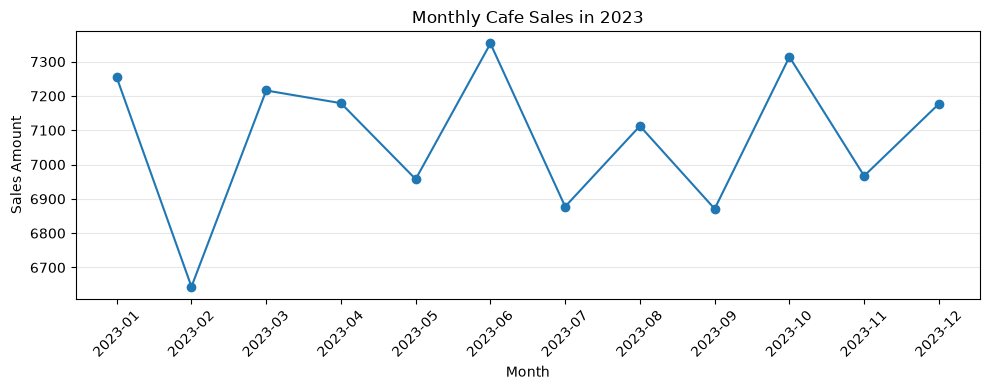

In [48]:
import matplotlib.pyplot as plt

months = monthly_sales["Month"].astype(str)
sales  = monthly_sales["Sales Amount"]

fig, ax = plt.subplots(figsize=(10,4))

ax.plot(months,sales, marker="o")
ax.set_title("Monthly Cafe Sales in 2023")
ax.set_xlabel("Month")
ax.set_ylabel("Sales Amount")
ax.tick_params(axis="x",labelrotation=45)
ax.grid(axis="y",alpha=0.3)

fig.tight_layout()
plt.show()

### Plot Top 5 items by sales

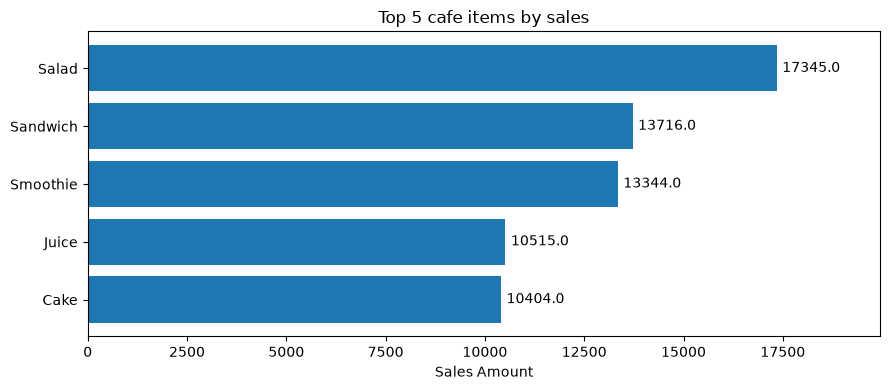

In [61]:
top_items = known_items.sort_values(
    "Sales Amount",
    ascending=False).head(5)

fig , ax = plt.subplots(figsize=(9,4))

bars = ax.barh(top_items["Item"],top_items["Sales Amount"])
ax.invert_yaxis()

ax.set_title("Top 5 cafe items by sales")
ax.set_xlabel("Sales Amount")
ax.bar_label(bars ,fmt="%.1f",padding=4)
ax.margins(x=0.15)

fig.tight_layout()
plt.show()

### Plot Top 5 items by Quantity

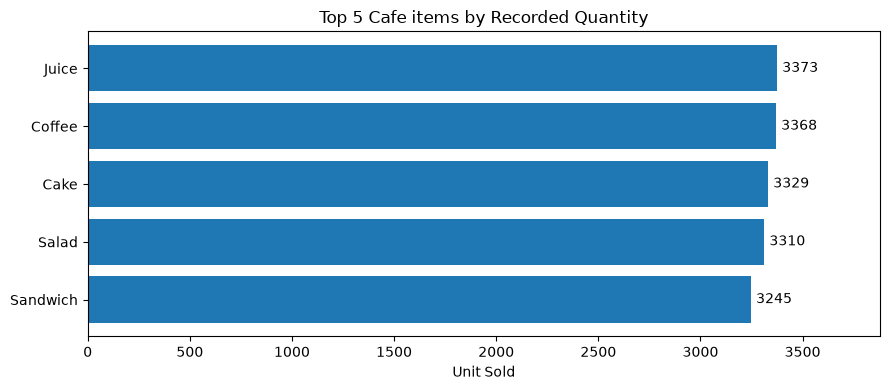

In [64]:
top_items_by_quantity = known_items.sort_values("Quantity", ascending=False).head(5)

fig , ax = plt.subplots(figsize=(9,4))

bars = ax.barh(top_items_by_quantity["Item"],top_items_by_quantity["Quantity"])
ax.invert_yaxis()

ax.set_title("Top 5 Cafe items by Recorded Quantity")
ax.set_xlabel("Unit Sold")
ax.bar_label(bars,fmt="%.0f",padding=4)
ax.margins(x=0.15)

fig.tight_layout()
plt.show()

### Plot Average Sales by Day of the week

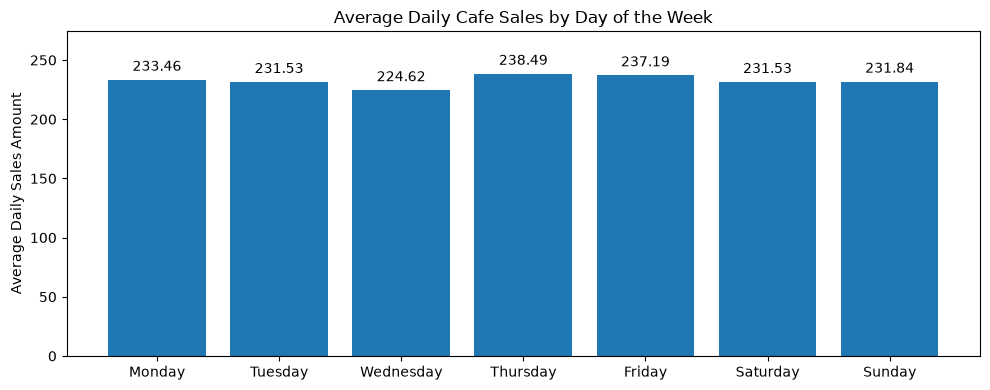

In [66]:
average_sales = weekday_sales["average_daily_sales"]

fig , ax = plt.subplots(figsize=(10,4))

bars = ax.bar(average_sales.index,average_sales)
ax.bar_label(bars,fmt="%.2f",padding=4)

ax.set_title("Average Daily Cafe Sales by Day of the Week")
ax.set_ylabel("Average Daily Sales Amount")
ax.margins(y=0.15)

fig.tight_layout()
plt.show()

### Plot Sales by Payment Method and Location

   Payment Method  total_rows  rows_with_sales_amount  total_sales
0         Unknown        3178                    3169      27813.5
1     Credit Card        2273                    2269      20466.0
2  Digital Wallet        2291                    2285      20414.0
3            Cash        2258                    2254      20402.5

   Location  total_rows  rows_with_sales_amount  total_sales
0   Unknown        3961                    3953      35369.5
1  In-store        3017                    3008      27174.0
2  Takeaway        3022                    3016      26552.5



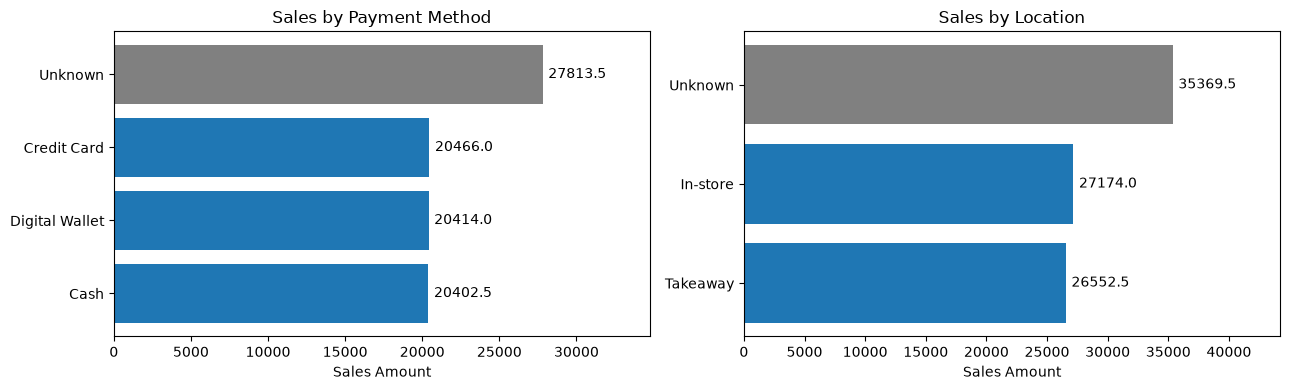

In [72]:
fig ,(ax_payment,ax_location) = plt.subplots(1,2,figsize=(13,4))

for ax,summary,category,title in [(ax_payment,payment_sales,"Payment Method","Sales by Payment Method"),
        (ax_location,location_sales,"Location","Sales by Location")]:
    chart_data = summary.sort_values("total_sales",ascending=False)

    print(chart_data)
    print("")

    colors = [
        "gray" if name == "Unknown" else "tab:blue"
         for name in chart_data[category]
    ]

    bars = ax.barh(chart_data[category],chart_data["total_sales"],color=colors)
    ax.invert_yaxis()
    ax.bar_label(bars,fmt="%.1f",padding=4)
    ax.margins(x=0.25)
    ax.set_title(title)
    ax.set_xlabel("Sales Amount")

fig.tight_layout()
plt.show()
   

recorded sales = 84763.5
sales_with_recovery = 